In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 80)
from src import config as C

# 05 - Robustness to controlled perturbations
`degradation = original_f1 - perturbed_f1` (macro-F1 on matched original/perturbed pairs; our own definition, not a standard benchmark metric). Perturbations are random noise, not optimised adversarial attacks. Run: `python -m src.robustness`.

In [2]:
rob = pd.read_csv(C.RESULTS_DIR / 'robustness_results.csv')
sub = rob[(rob.language_slice=='All') & (rob.model_id.isin(['char_lr','word_lr','char_svm','word_svm']))]
display(sub.pivot_table(index='perturbation_type', columns='model_id', values='degradation').round(4))

model_id,char_lr,char_svm,word_lr,word_svm
perturbation_type,,,,
ALL_TYPES (pooled),0.0052,0.0032,0.0013,0.0109
casing_variation,0.0000,0.0000,0.0000,0.0000
character_deletion,0.0060,0.0041,0.0097,0.0159
character_substitution,0.0144,0.0145,0.0125,0.0202
code_switching,0.0000,0.0022,0.0023,0.0000
informal_abbreviation,0.0025,0.0000,-0.0001,-0.0002
minor_noise,0.0001,0.0002,-0.0018,0.0098
punctuation_variation,0.0083,0.0022,0.0000,0.0000
roman_urdu_spelling_variation,0.0225,0.0000,-0.0717,0.0377


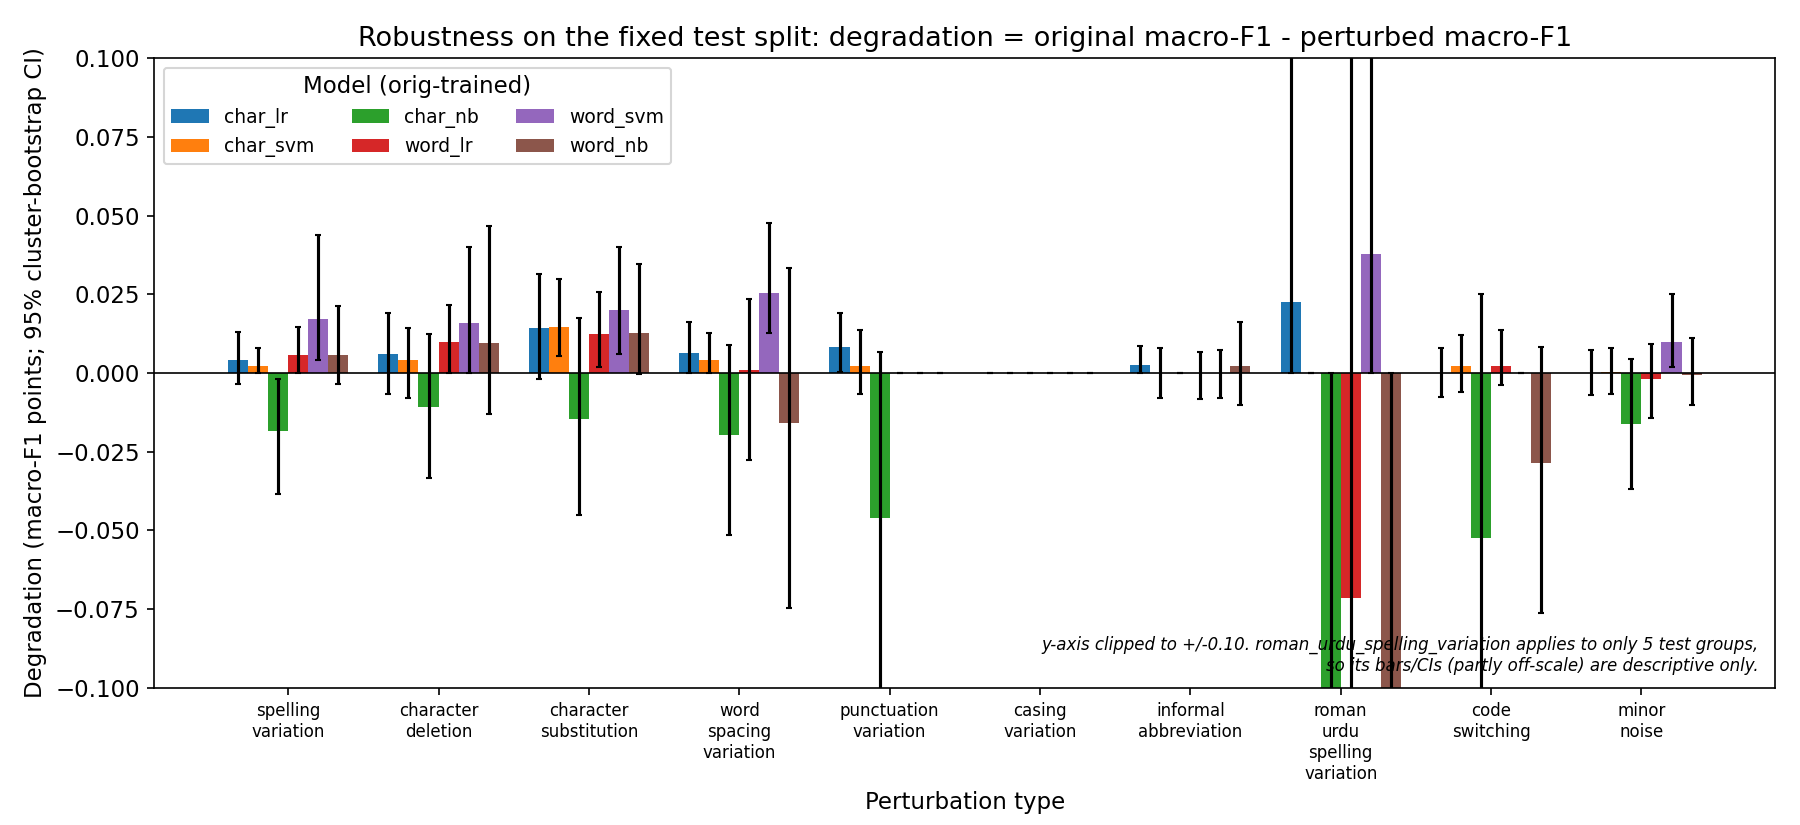

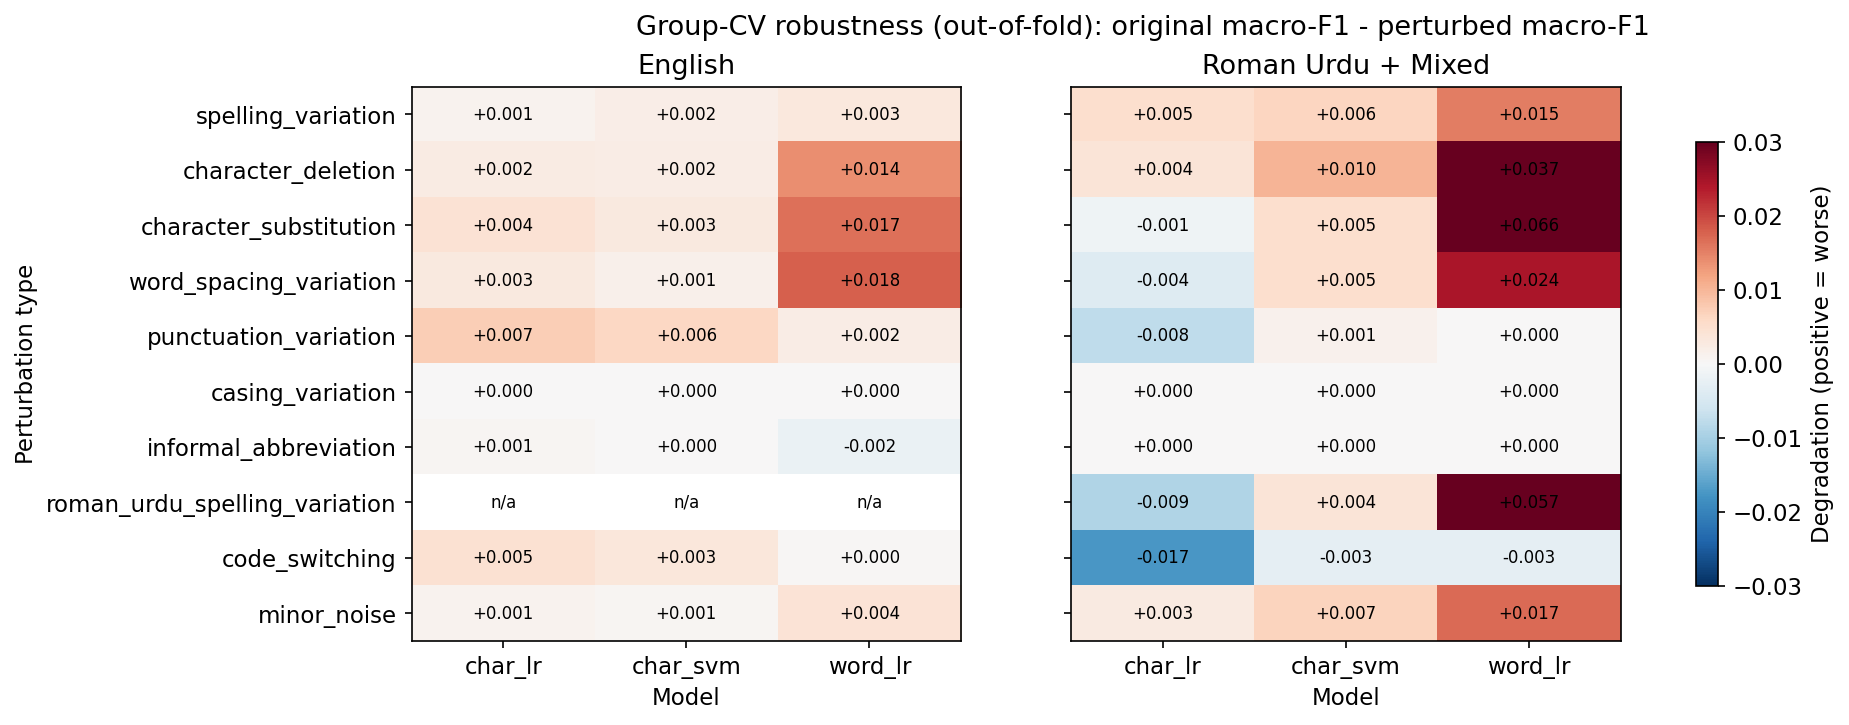

In [3]:
display(Image(str(C.FIGURES_DIR / 'results_robustness_by_type.png'), width=900))
display(Image(str(C.FIGURES_DIR / 'results_robustness_cv_heatmap.png'), width=900))

In [4]:
cvr = pd.read_csv(C.RESULTS_DIR / 'group_cv_robustness.csv')
display(cvr[(cvr.model_id=='char_lr') & (cvr.language_slice=='Roman Urdu + Mixed')][['perturbation_type','n_pairs','n_groups','original_f1','perturbed_f1','degradation','degradation_ci_low','degradation_ci_high','flip_rate']].round(4))

,perturbation_type,n_pairs,n_groups,original_f1,perturbed_f1,degradation,degradation_ci_low,degradation_ci_high,flip_rate
21,spelling_variation,782,22,0.9680,0.9628,0.0051,0.0000,0.0206,0.0230
22,character_deletion,789,22,0.9683,0.9645,0.0038,-0.0027,0.0153,0.0266
23,character_substitution,789,22,0.9683,0.9696,-0.0013,-0.0126,0.0084,0.0292
24,word_spacing_variation,777,22,0.9678,0.9717,-0.0039,-0.0152,0.0000,0.0142
25,punctuation_variation,789,22,0.9683,0.9759,-0.0076,-0.0272,0.0000,0.0101
26,casing_variation,789,22,0.9683,0.9683,0.0000,0.0000,0.0000,0.0000
27,informal_abbreviation,334,13,0.9568,0.9568,0.0000,0.0000,0.0000,0.0000
28,roman_urdu_spelling_variation,776,21,0.9677,0.9768,-0.0091,-0.0460,0.0102,0.0168
29,code_switching,750,19,0.9732,0.9906,-0.0175,-0.0716,0.0000,0.0173
30,minor_noise,762,22,0.9685,0.9659,0.0026,0.0000,0.0088,0.0157
